In [ ]:
# Install required packages
!pip install tensorflow matplotlib pandas seaborn scikit-learn

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix
import time

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Check if GPU is available
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))
print("TensorFlow version:", tf.__version__)

Num GPUs Available:  1
TensorFlow version: 2.18.0


In [ ]:
# Install Kaggle
!pip install kaggle

In [ ]:
# Upload your kaggle.json file
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"uncagedmorals7","key":"168ac2fde603be520ff91710aa74f95c"}'}

In [ ]:
# Make directory for Kaggle API token
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
# Download the dataset
!kaggle datasets download -d rm1000/augmented-apple-disease-detection-dataset

Dataset URL: https://www.kaggle.com/datasets/rm1000/augmented-apple-disease-detection-dataset
License(s): CC0-1.0
 96% 573M/599M [00:05<00:00, 154MB/s]
100% 599M/599M [00:05<00:00, 111MB/s]


In [ ]:
# Unzip the dataset
!unzip -q augmented-apple-disease-detection-dataset.zip

In [ ]:
# Check the directory structure
!ls -la

total 613696
drwxr-xr-x 1 root root      4096 Jun 13 04:25 .
drwxr-xr-x 1 root root      4096 Jun 13 04:09 ..
-rw-r--r-- 1 root root 628389505 Feb 21  2023 augmented-apple-disease-detection-dataset.zip
drwxr-xr-x 4 root root      4096 Jun 11 13:37 .config
drwx------ 6 root root      4096 Jun 13 04:21 drive
-rw-r--r-- 1 root root        70 Jun 13 04:24 kaggle.json
drwxr-xr-x 1 root root      4096 Jun 11 13:37 sample_data
drwxr-xr-x 6 root root      4096 Jun 13 04:25 train_augmented


In [ ]:
# Check the train_augmented directory
!ls -la train_augmented

total 820
drwxr-xr-x 6 root root   4096 Jun 13 04:25  .
drwxr-xr-x 1 root root   4096 Jun 13 04:25  ..
drwxr-xr-x 2 root root 204800 Jun 13 04:25 'Apple Scab'
drwxr-xr-x 2 root root 217088 Jun 13 04:25 'Black Rot'
drwxr-xr-x 2 root root 221184 Jun 13 04:25 'Cedar Apple Rust'
drwxr-xr-x 2 root root 188416 Jun 13 04:25  Healthy


In [ ]:
# Define the dataset directory
data_dir = 'train_augmented'

# Define class names
class_names = ['Apple Scab', 'Black Rot', 'Cedar Apple Rust', 'Healthy']

# Count images in each class
for cls in class_names:
    class_path = os.path.join(data_dir, cls)
    if os.path.isdir(class_path):
        num_images = len(os.listdir(class_path))
        print(f"{cls}: {num_images} images")

Apple Scab: 3000 images
Black Rot: 3000 images
Cedar Apple Rust: 3000 images
Healthy: 3000 images


In [ ]:
import shutil
from sklearn.model_selection import train_test_split

# Create directories for train, validation, and test sets
base_dir = 'apple_disease_dataset'
os.makedirs(base_dir, exist_ok=True)

train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'validation')
test_dir = os.path.join(base_dir, 'test')

os.makedirs(train_dir, exist_ok=True)
os.makedirs(val_dir, exist_ok=True)
os.makedirs(test_dir, exist_ok=True)

# Create class directories in each split
for class_name in class_names:
    os.makedirs(os.path.join(train_dir, class_name), exist_ok=True)
    os.makedirs(os.path.join(val_dir, class_name), exist_ok=True)
    os.makedirs(os.path.join(test_dir, class_name), exist_ok=True)

# Split and copy files
for class_name in class_names:
    # Path to class directory in the original dataset
    class_dir = os.path.join(data_dir, class_name)

    if os.path.exists(class_dir):
        # Get all image files
        image_files = [f for f in os.listdir(class_dir) if f.endswith('.jpg') or f.endswith('.jpeg') or f.endswith('.png')]

        # Split into train (70%), validation (15%), and test (15%)
        train_files, temp_files = train_test_split(image_files, test_size=0.3, random_state=42)
        val_files, test_files = train_test_split(temp_files, test_size=0.5, random_state=42)

        # Copy files to respective directories
        for file in train_files:
            shutil.copy(os.path.join(class_dir, file), os.path.join(train_dir, class_name, file))

        for file in val_files:
            shutil.copy(os.path.join(class_dir, file), os.path.join(val_dir, class_name, file))

        for file in test_files:
            shutil.copy(os.path.join(class_dir, file), os.path.join(test_dir, class_name, file))

        print(f"Class {class_name}: {len(train_files)} training, {len(val_files)} validation, {len(test_files)} test images")

Class Apple Scab: 1075 training, 230 validation, 231 test images
Class Black Rot: 1075 training, 230 validation, 231 test images
Class Cedar Apple Rust: 1075 training, 230 validation, 231 test images
Class Healthy: 1075 training, 230 validation, 231 test images


In [ ]:
from tensorflow.keras.applications.efficientnet import preprocess_input

# Image dimensions
IMG_SIZE = 256
BATCH_SIZE = 32

# Data generators with only preprocessing (no additional augmentation)
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2  # Use 20% of training data as validation
)

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

# Load images from directory
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True,
    subset='training',
    color_mode='rgb'
)

validation_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False,
    subset='validation',
    color_mode='rgb'
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False,
    color_mode='rgb'
)

# Get class indices
class_indices = train_generator.class_indices
print("Class indices:", class_indices)

# Create a reverse mapping
idx_to_class = {v: k for k, v in class_indices.items()}
print("Index to class mapping:", idx_to_class)

Found 3440 images belonging to 4 classes.
Found 860 images belonging to 4 classes.
Found 924 images belonging to 4 classes.
Class indices: {'Apple Scab': 0, 'Black Rot': 1, 'Cedar Apple Rust': 2, 'Healthy': 3}
Index to class mapping: {0: 'Apple Scab', 1: 'Black Rot', 2: 'Cedar Apple Rust', 3: 'Healthy'}


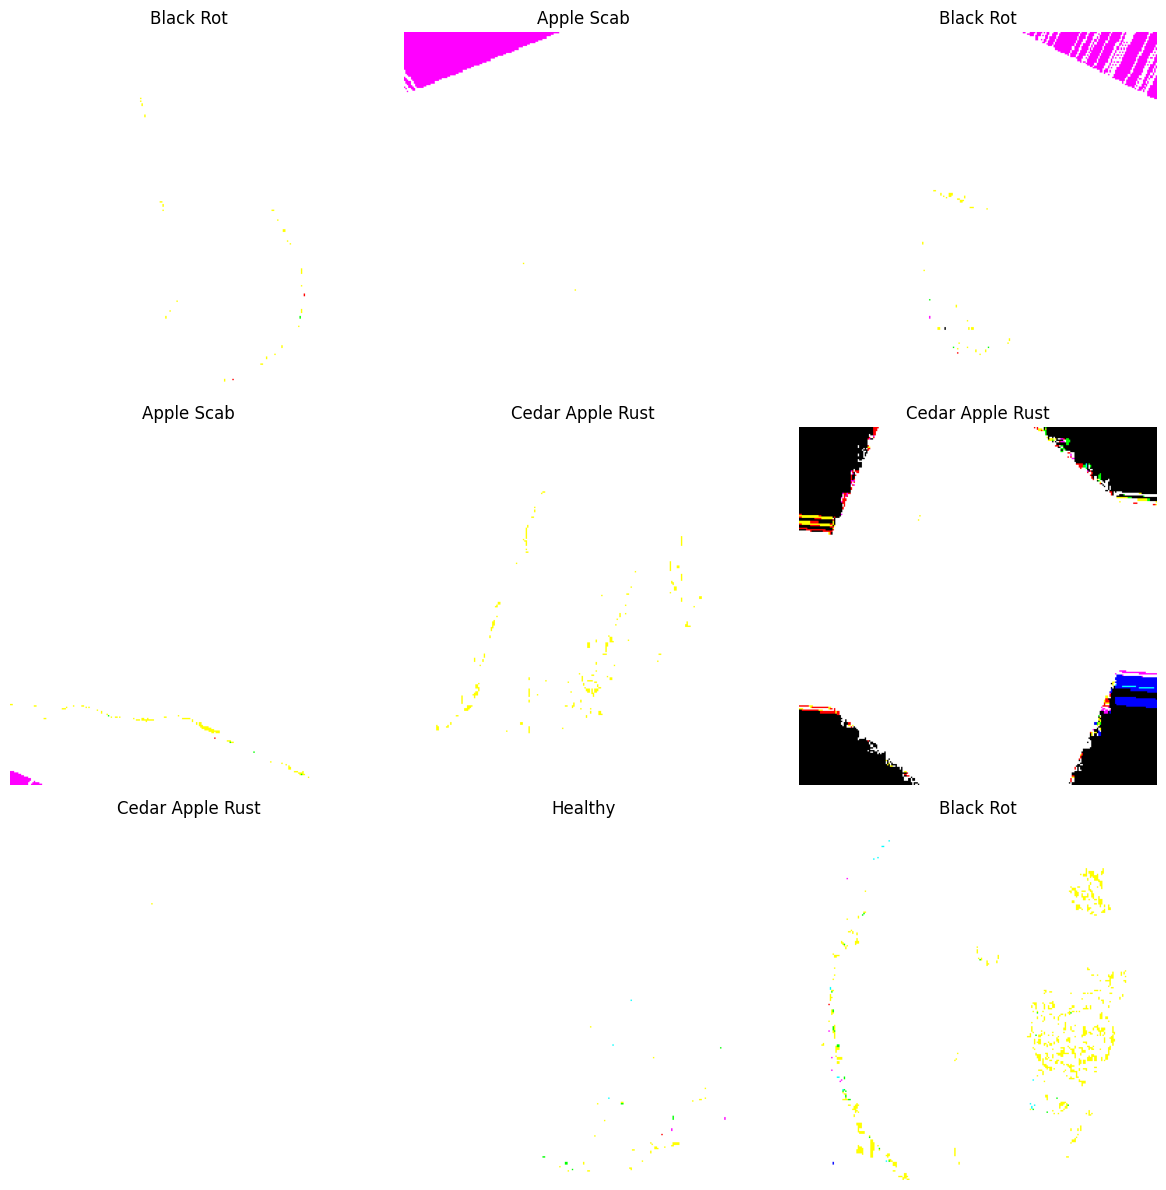

In [ ]:
def show_batch(image_batch, label_batch):
    plt.figure(figsize=(12, 12))
    for i in range(min(9, len(image_batch))):
        ax = plt.subplot(3, 3, i + 1)
        # Undo preprocessing to display the image
        img = image_batch[i]
        # For EfficientNet preprocessing
        img = img * 255.0  # Scale back to [0, 255]
        img = np.clip(img, 0, 255).astype('uint8')
        plt.imshow(img)
        # Get the class name
        idx = np.argmax(label_batch[i])
        class_name = idx_to_class[idx]
        plt.title(class_name)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

# Get a batch of training images and labels
image_batch, label_batch = next(train_generator)
show_batch(image_batch, label_batch)

# corrected code for full version of **images**

In [ ]:
def show_batch(image_batch, label_batch):
    plt.figure(figsize=(12, 12))
    for i in range(min(9, len(image_batch))):
        ax = plt.subplot(3, 3, i + 1)

        # Correct inverse of EfficientNet preprocessing
        img = image_batch[i]
        img = (img + 1.0) * 127.5  # Rescale from [-1,1] back to [0,255]
        img = np.clip(img, 0, 255).astype('uint8')

        plt.imshow(img)
        idx = np.argmax(label_batch[i])
        class_name = idx_to_class[idx]
        plt.title(class_name)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


In [ ]:
# Number of classes
NUM_CLASSES = len(class_indices)

# Create the base model from EfficientNetB0
base_model = EfficientNetB0(
    include_top=False,  # Don't include the top (classification) layer
    weights="imagenet",  # Use pre-trained weights on ImageNet
    input_shape=(IMG_SIZE, IMG_SIZE, 3),  # Input shape for our images
    pooling='avg'  # Use average pooling
)

# Freeze the base model layers
base_model.trainable = False

# Create the model with custom top layers
model = models.Sequential([
    base_model,
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation='softmax')  # 4 classes
])

# Display the model summary
model.summary()



Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 1280)           │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,384,679 (16.73 MB)

 Trainable params: 332,036 (1.27 MB)

 Non-trainable params: 4,052,643 (15.46 MB)

In [ ]:
import datetime


In [ ]:
# Define callbacks
checkpoint_path = "apple_disease_model_best.h5"
checkpoint = ModelCheckpoint(
    checkpoint_path,
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

# TensorBoard callback for visualization
log_dir = "logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
tensorboard_callback = tf.keras.callbacks.TensorBoard(
    log_dir=log_dir,
    histogram_freq=1
)

callbacks = [checkpoint, early_stopping, reduce_lr, tensorboard_callback]

In [ ]:
# Compile the model
model.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Calculate steps per epoch and validation steps
steps_per_epoch = train_generator.samples // BATCH_SIZE
validation_steps = validation_generator.samples // BATCH_SIZE

# Record start time
start_time = time.time()

# Train the model (feature extraction phase)
history = model.fit(
    train_generator,
    steps_per_epoch=steps_per_epoch,
    epochs=20,
    validation_data=validation_generator,
    validation_steps=validation_steps,
    callbacks=callbacks
)

# Record end time
end_time = time.time()
print(f"Training time for phase 1: {(end_time - start_time) / 60:.2f} minutes")

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 258ms/step - accuracy: 0.7661 - loss: 0.6960
Epoch 1: val_accuracy improved from -inf to 0.93990, saving model to apple_disease_model_best.h5


107/107 ━━━━━━━━━━━━━━━━━━━━ 73s 407ms/step - accuracy: 0.7670 - loss: 0.6932 - val_accuracy: 0.9399 - val_loss: 0.2268 - learning_rate: 0.0010
Epoch 2/20
  1/107 ━━━━━━━━━━━━━━━━━━━━ 6s 60ms/step - accuracy: 0.9375 - loss: 0.2425

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/epoch_iterator.py:107: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 2: val_accuracy improved from 0.93990 to 0.94231, saving model to apple_disease_model_best.h5


107/107 ━━━━━━━━━━━━━━━━━━━━ 8s 76ms/step - accuracy: 0.9375 - loss: 0.2425 - val_accuracy: 0.9423 - val_loss: 0.2240 - learning_rate: 0.0010
Epoch 3/20
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 0.9436 - loss: 0.1472
Epoch 3: val_accuracy improved from 0.94231 to 0.97716, saving model to apple_disease_model_best.h5


107/107 ━━━━━━━━━━━━━━━━━━━━ 21s 197ms/step - accuracy: 0.9436 - loss: 0.1472 - val_accuracy: 0.9772 - val_loss: 0.1023 - learning_rate: 0.0010
Epoch 4/20
  1/107 ━━━━━━━━━━━━━━━━━━━━ 6s 59ms/step - accuracy: 0.9062 - loss: 0.3355
Epoch 4: val_accuracy did not improve from 0.97716
107/107 ━━━━━━━━━━━━━━━━━━━━ 8s 75ms/step - accuracy: 0.9062 - loss: 0.3355 - val_accuracy: 0.9772 - val_loss: 0.1018 - learning_rate: 0.0010
Epoch 5/20
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: 0.9505 - loss: 0.1301
Epoch 5: val_accuracy improved from 0.97716 to 0.98438, saving model to apple_disease_model_best.h5


107/107 ━━━━━━━━━━━━━━━━━━━━ 41s 276ms/step - accuracy: 0.9506 - loss: 0.1300 - val_accuracy: 0.9844 - val_loss: 0.0556 - learning_rate: 0.0010
Epoch 6/20
  1/107 ━━━━━━━━━━━━━━━━━━━━ 6s 61ms/step - accuracy: 0.9375 - loss: 0.1476
Epoch 6: val_accuracy did not improve from 0.98438
107/107 ━━━━━━━━━━━━━━━━━━━━ 7s 62ms/step - accuracy: 0.9375 - loss: 0.1476 - val_accuracy: 0.9844 - val_loss: 0.0547 - learning_rate: 0.0010
Epoch 7/20
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - accuracy: 0.9629 - loss: 0.1023
Epoch 7: val_accuracy did not improve from 0.98438
107/107 ━━━━━━━━━━━━━━━━━━━━ 22s 205ms/step - accuracy: 0.9628 - loss: 0.1023 - val_accuracy: 0.9844 - val_loss: 0.0453 - learning_rate: 0.0010
Epoch 8/20
  1/107 ━━━━━━━━━━━━━━━━━━━━ 6s 58ms/step - accuracy: 0.9688 - loss: 0.1063
Epoch 8: val_accuracy did not improve from 0.98438
107/107 ━━━━━━━━━━━━━━━━━━━━ 6s 59ms/step - accuracy: 0.9688 - loss: 0.1063 - val_accuracy: 0.9844 - val_loss: 0.0453 - learning_rate: 0.0010
Epoch 9/20
10

107/107 ━━━━━━━━━━━━━━━━━━━━ 84s 502ms/step - accuracy: 0.9668 - loss: 0.0897 - val_accuracy: 0.9880 - val_loss: 0.0397 - learning_rate: 0.0010
Epoch 12/20
  1/107 ━━━━━━━━━━━━━━━━━━━━ 6s 63ms/step - accuracy: 1.0000 - loss: 0.0410
Epoch 12: val_accuracy did not improve from 0.98798
107/107 ━━━━━━━━━━━━━━━━━━━━ 7s 61ms/step - accuracy: 1.0000 - loss: 0.0410 - val_accuracy: 0.9880 - val_loss: 0.0405 - learning_rate: 0.0010
Epoch 13/20
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.9705 - loss: 0.0819
Epoch 13: val_accuracy did not improve from 0.98798
107/107 ━━━━━━━━━━━━━━━━━━━━ 41s 386ms/step - accuracy: 0.9705 - loss: 0.0819 - val_accuracy: 0.9880 - val_loss: 0.0409 - learning_rate: 0.0010
Epoch 14/20
  1/107 ━━━━━━━━━━━━━━━━━━━━ 6s 61ms/step - accuracy: 1.0000 - loss: 0.0136
Epoch 14: val_accuracy did not improve from 0.98798
107/107 ━━━━━━━━━━━━━━━━━━━━ 10s 95ms/step - accuracy: 1.0000 - loss: 0.0136 - val_accuracy: 0.9868 - val_loss: 0.0413 - learning_rate: 0.0010
Epoch 

107/107 ━━━━━━━━━━━━━━━━━━━━ 35s 215ms/step - accuracy: 0.9704 - loss: 0.0891 - val_accuracy: 0.9892 - val_loss: 0.0385 - learning_rate: 0.0010
Epoch 18/20
  1/107 ━━━━━━━━━━━━━━━━━━━━ 6s 59ms/step - accuracy: 1.0000 - loss: 0.0275
Epoch 18: val_accuracy did not improve from 0.98918
107/107 ━━━━━━━━━━━━━━━━━━━━ 7s 65ms/step - accuracy: 1.0000 - loss: 0.0275 - val_accuracy: 0.9892 - val_loss: 0.0382 - learning_rate: 0.0010
Epoch 19/20
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: 0.9674 - loss: 0.0844
Epoch 19: val_accuracy did not improve from 0.98918
107/107 ━━━━━━━━━━━━━━━━━━━━ 23s 213ms/step - accuracy: 0.9674 - loss: 0.0844 - val_accuracy: 0.9856 - val_loss: 0.0301 - learning_rate: 0.0010
Epoch 20/20
  1/107 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 1.0000 - loss: 0.0312
Epoch 20: val_accuracy did not improve from 0.98918
107/107 ━━━━━━━━━━━━━━━━━━━━ 7s 65ms/step - accuracy: 1.0000 - loss: 0.0312 - val_accuracy: 0.9856 - val_loss: 0.0299 - learning_rate: 0.0010
Restori

In [ ]:
# Unfreeze the top layers of the base model
base_model.trainable = True

# Freeze all the layers except the last 20
for layer in base_model.layers[:-20]:
    layer.trainable = False

# Recompile the model with a lower learning rate
model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Display the model summary after unfreezing layers
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 1280)           │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,384,679 (16.73 MB)

 Trainable params: 1,461,812 (5.58 MB)

 Non-trainable params: 2,922,867 (11.15 MB)

In [ ]:
# Update checkpoint path for phase 2
checkpoint_path = "apple_disease_model_phase2.h5"
checkpoint = ModelCheckpoint(
    checkpoint_path,
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

callbacks = [checkpoint, early_stopping, reduce_lr]

# Record start time
start_time = time.time()

# Train the model (fine-tuning phase)
fine_tune_history = model.fit(
    train_generator,
    steps_per_epoch=steps_per_epoch,
    epochs=30,
    validation_data=validation_generator,
    validation_steps=validation_steps,
    callbacks=callbacks,
    initial_epoch=history.epoch[-1] + 1
)

# Record end time
end_time = time.time()
print(f"Training time for phase 2: {(end_time - start_time) / 60:.2f} minutes")

Epoch 21/30
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 273ms/step - accuracy: 0.8958 - loss: 0.2921
Epoch 21: val_accuracy improved from -inf to 0.98077, saving model to apple_disease_model_phase2.h5


107/107 ━━━━━━━━━━━━━━━━━━━━ 76s 388ms/step - accuracy: 0.8958 - loss: 0.2920 - val_accuracy: 0.9808 - val_loss: 0.0491 - learning_rate: 1.0000e-05
Epoch 22/30
  1/107 ━━━━━━━━━━━━━━━━━━━━ 6s 60ms/step - accuracy: 0.9688 - loss: 0.1710
Epoch 22: val_accuracy did not improve from 0.98077
107/107 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.9688 - loss: 0.1710 - val_accuracy: 0.9808 - val_loss: 0.0494 - learning_rate: 1.0000e-05
Epoch 23/30
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step - accuracy: 0.9165 - loss: 0.2658
Epoch 23: val_accuracy did not improve from 0.98077
107/107 ━━━━━━━━━━━━━━━━━━━━ 17s 162ms/step - accuracy: 0.9166 - loss: 0.2656 - val_accuracy: 0.9772 - val_loss: 0.0576 - learning_rate: 1.0000e-05
Epoch 24/30
  1/107 ━━━━━━━━━━━━━━━━━━━━ 6s 57ms/step - accuracy: 1.0000 - loss: 0.0185
Epoch 24: val_accuracy did not improve from 0.98077
107/107 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 1.0000 - loss: 0.0185 - val_accuracy: 0.9760 - val_loss: 0.0578 - learning_rate: 1.

In [ ]:
# Evaluate the model on test data
test_loss, test_accuracy = model.evaluate(test_generator)
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test loss: {test_loss:.4f}")

29/29 ━━━━━━━━━━━━━━━━━━━━ 10s 338ms/step - accuracy: 0.9519 - loss: 0.1461
Test accuracy: 0.9751
Test loss: 0.0707


In [ ]:
# Get predictions on test data
test_generator.reset()
steps = int(np.ceil(test_generator.samples / BATCH_SIZE))  # fix here
y_pred = model.predict(test_generator, steps=steps)
y_pred_classes = np.argmax(y_pred, axis=1)

# Get true labels
y_true = test_generator.classes[:len(y_pred_classes)]

# Print classification report
print("Classification Report:")
print(classification_report(y_true, y_pred_classes, target_names=list(class_indices.keys())))


29/29 ━━━━━━━━━━━━━━━━━━━━ 17s 359ms/step
Classification Report:
                  precision    recall  f1-score   support

      Apple Scab       0.99      0.93      0.96       231
       Black Rot       0.97      1.00      0.99       231
Cedar Apple Rust       0.95      1.00      0.97       231
         Healthy       0.98      0.98      0.98       231

        accuracy                           0.98       924
       macro avg       0.98      0.98      0.97       924
    weighted avg       0.98      0.98      0.97       924



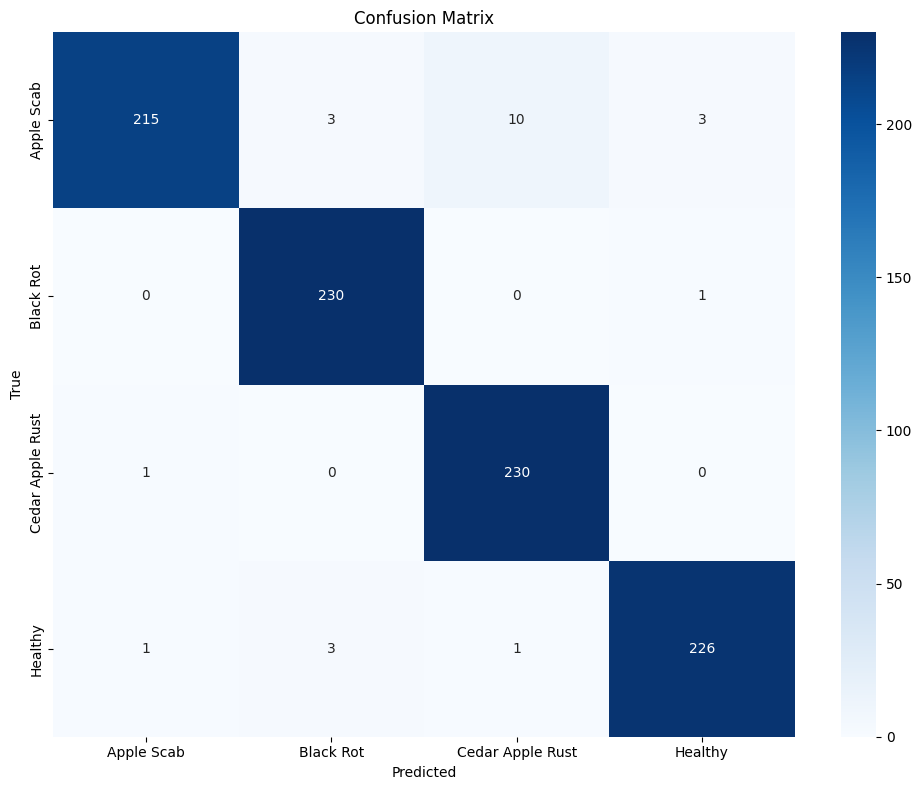

In [ ]:
# Plot confusion matrix
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_true, y_pred_classes)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=list(class_indices.keys()),
            yticklabels=list(class_indices.keys()))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

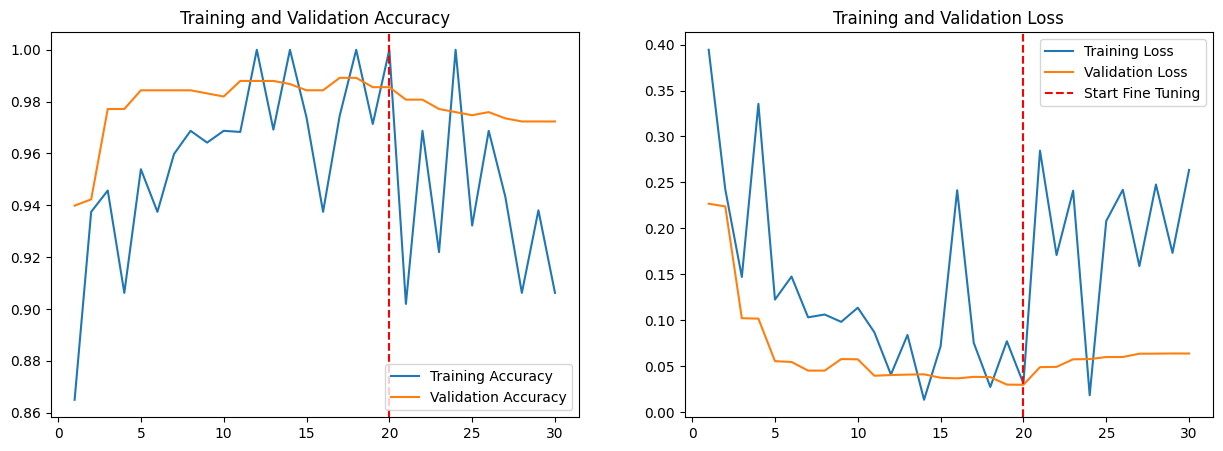

In [ ]:
# Combine histories from both phases
acc = history.history['accuracy'] + fine_tune_history.history['accuracy']
val_acc = history.history['val_accuracy'] + fine_tune_history.history['val_accuracy']
loss = history.history['loss'] + fine_tune_history.history['loss']
val_loss = history.history['val_loss'] + fine_tune_history.history['val_loss']

# Create epoch range
epochs_range = range(1, len(acc) + 1)

# Plot training and validation accuracy
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.axvline(x=len(history.history['accuracy']), color='r', linestyle='--')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

# Plot training and validation loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.axvline(x=len(history.history['loss']), color='r', linestyle='--', label='Start Fine Tuning')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [ ]:
# Save the final model
model.save('apple_disease_model_final.h5')

# Save the class indices for later use
import json
with open('class_indices.json', 'w') as f:
    json.dump(class_indices, f)

print("Model and class indices saved successfully!")

Model and class indices saved successfully!


In [ ]:
def predict_image(image_path):
    # Load and preprocess the image
    img = keras.preprocessing.image.load_img(image_path, target_size=(IMG_SIZE, IMG_SIZE))
    img_array = keras.preprocessing.image.img_to_array(img)
    img_array = preprocess_input(img_array)  # Apply EfficientNet preprocessing
    img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension

    # Make prediction
    predictions = model.predict(img_array)
    predicted_class_idx = np.argmax(predictions[0])
    predicted_class = idx_to_class[predicted_class_idx]
    confidence = predictions[0][predicted_class_idx] * 100

    # Display the image and prediction
    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.title(f"Prediction: {predicted_class} ({confidence:.2f}%)")
    plt.axis('off')
    plt.show()

    # Display all class probabilities
    plt.figure(figsize=(10, 5))
    plt.bar(list(idx_to_class.values()), predictions[0] * 100)
    plt.xlabel('Class')
    plt.ylabel('Probability (%)')
    plt.title('Class Probabilities')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    return predicted_class, confidence

In [ ]:
# Function to allow user to input an image path for prediction
def predict_user_image():
    # Option 1: Upload an image
    print("Option 1: Upload an image")
    uploaded = files.upload()

    for filename in uploaded.keys():
        print(f"\nPredicting on uploaded image: {filename}")
        predicted_class, confidence = predict_image(filename)
        print(f"Prediction: {predicted_class} with {confidence:.2f}% confidence")

    # Option 2: Enter a path to an existing image
    print("\nOption 2: Enter a path to an existing image in the dataset")
    image_path = input("Enter the path to the image (e.g., 'apple_disease_dataset/test/Healthy/image.jpg'): ")

    if os.path.exists(image_path):
        predicted_class, confidence = predict_image(image_path)
        print(f"Prediction: {predicted_class} with {confidence:.2f}% confidence")
    else:
        print(f"Error: File {image_path} does not exist.")

Option 1: Upload an image


Saving _1052_1616117.png to _1052_1616117.png

Predicting on uploaded image: _1052_1616117.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step


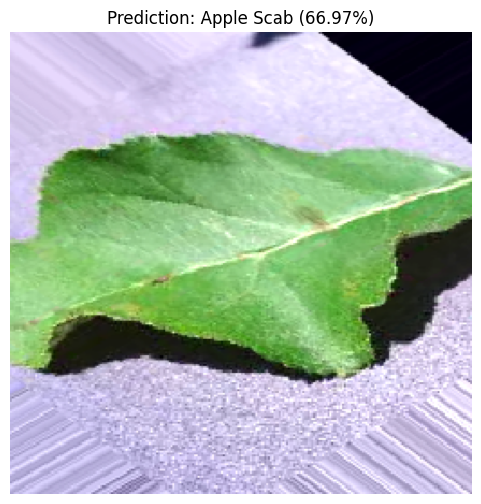

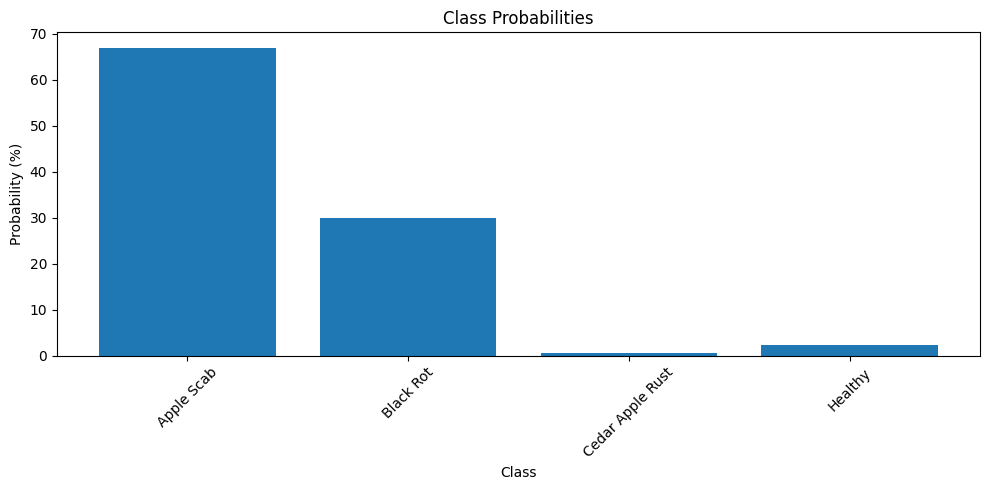

Prediction: Apple Scab with 66.97% confidence

Option 2: Enter a path to an existing image in the dataset
Enter the path to the image (e.g., 'apple_disease_dataset/test/Healthy/image.jpg'): /content/apple_disease_dataset/test/Cedar Apple Rust/_1021_2125535.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step


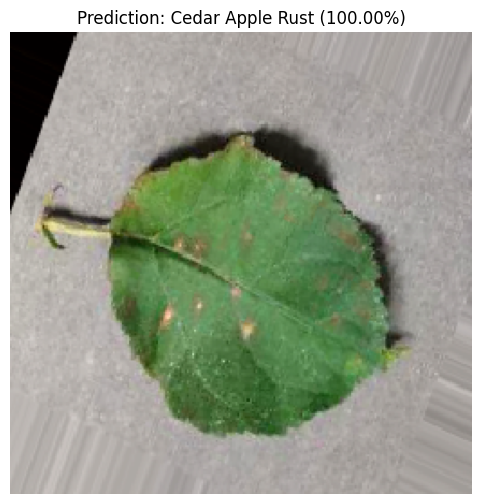

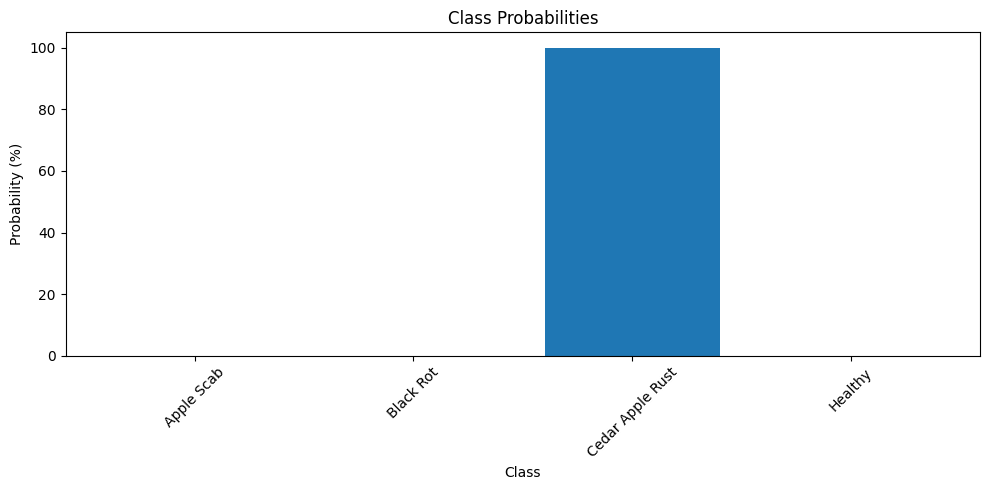

Prediction: Cedar Apple Rust with 100.00% confidence


In [ ]:
# Run the prediction function
predict_user_image()

In [ ]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    # First, we create a model that maps the input image to the activations
    # of the last conv layer as well as the output predictions
    grad_model = tf.keras.models.Model(
        [model.inputs],
        [model.get_layer(last_conv_layer_name).output, model.output]
    )

    # Then, we compute the gradient of the top predicted class for our input image
    # with respect to the activations of the last conv layer
    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    # This is the gradient of the output neuron with respect to
    # the output feature map of the last conv layer
    grads = tape.gradient(class_channel, last_conv_layer_output)

    # This is a vector where each entry is the mean intensity of the gradient
    # over a specific feature map channel
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # We multiply each channel in the feature map array
    # by "how important this channel is" with regard to the top predicted class
    # then sum all the channels to obtain the heatmap class activation
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # For visualization purpose, we will also normalize the heatmap between 0 & 1
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

In [ ]:
def display_gradcam(image_path, heatmap, alpha=0.4):
    # Load the original image
    img = keras.preprocessing.image.load_img(image_path, target_size=(IMG_SIZE, IMG_SIZE))
    img = keras.preprocessing.image.img_to_array(img)

    # Rescale heatmap to 0-255
    heatmap = np.uint8(255 * heatmap)

    # Use jet colormap to colorize heatmap
    jet = plt.cm.get_cmap("jet")
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap]

    # Create an image with RGB colorized heatmap
    jet_heatmap = keras.preprocessing.image.array_to_img(jet_heatmap)
    jet_heatmap = jet_heatmap.resize((img.shape[1], img.shape[0]))
    jet_heatmap = keras.preprocessing.image.img_to_array(jet_heatmap)

    # Superimpose the heatmap on original image
    superimposed_img = jet_heatmap * alpha + img
    superimposed_img = keras.preprocessing.image.array_to_img(superimposed_img)

    # Display the original image and the heatmap
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 3, 1)
    plt.imshow(img / 255.0)
    plt.title('Original Image')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(heatmap, cmap='jet')
    plt.title('Grad-CAM Heatmap')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(superimposed_img)
    plt.title('Superimposed Image')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
def analyze_with_gradcam(image_path):
    # Load and preprocess the image
    img = keras.preprocessing.image.load_img(image_path, target_size=(IMG_SIZE, IMG_SIZE))
    img_array = keras.preprocessing.image.img_to_array(img)
    img_array = preprocess_input(img_array)  # Apply EfficientNet preprocessing
    img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension

    # Make prediction
    predictions = model.predict(img_array)
    predicted_class_idx = np.argmax(predictions[0])
    predicted_class = idx_to_class[predicted_class_idx]
    confidence = predictions[0][predicted_class_idx] * 100

    print(f"Prediction: {predicted_class} with {confidence:.2f}% confidence")

    # Find the last convolutional layer in the model
    last_conv_layer_name = None
    for layer in reversed(base_model.layers):
        if isinstance(layer, tf.keras.layers.Conv2D):
            last_conv_layer_name = layer.name
            break

    if last_conv_layer_name is None:
        print("Could not find a convolutional layer in the model.")
        return

    # Generate class activation heatmap
    heatmap = make_gradcam_heatmap(img_array, model, last_conv_layer_name)

    # Display the heatmap
    display_gradcam(image_path, heatmap)

In [ ]:
# Test Grad-CAM on a sample image
def test_gradcam():
    # Option 1: Upload an image
    print("Option 1: Upload an image for Grad-CAM analysis")
    uploaded = files.upload()

    for filename in uploaded.keys():
        print(f"\nAnalyzing uploaded image: {filename}")
        analyze_with_gradcam(filename)

    # Option 2: Enter a path to an existing image
    print("\nOption 2: Enter a path to an existing image in the dataset")
    image_path = input("Enter the path to the image (e.g., 'apple_disease_dataset/test/Healthy/image.jpg'): ")

    if os.path.exists(image_path):
        analyze_with_gradcam(image_path)
    else:
        print(f"Error: File {image_path} does not exist.")

Model Performance Metrics:
      Metric     Value
0   Accuracy  0.975108
1  Precision  0.975581
2     Recall  0.975108
3   F1 Score  0.974971


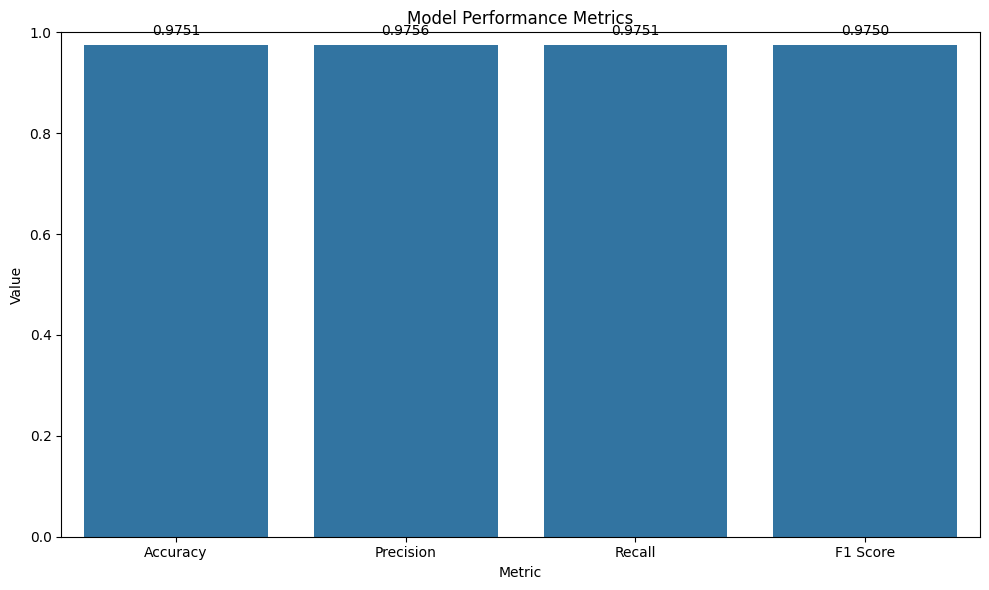

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred_classes)
precision = precision_score(y_true, y_pred_classes, average='weighted')
recall = recall_score(y_true, y_pred_classes, average='weighted')
f1 = f1_score(y_true, y_pred_classes, average='weighted')

# Create a DataFrame to display metrics
metrics_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Value': [accuracy, precision, recall, f1]
})

print("Model Performance Metrics:")
print(metrics_df)

# Plot metrics
plt.figure(figsize=(10, 6))
sns.barplot(x='Metric', y='Value', data=metrics_df)
plt.title('Model Performance Metrics')
plt.ylim(0, 1)
for i, v in enumerate(metrics_df['Value']):
    plt.text(i, v + 0.02, f"{v:.4f}", ha='center')
plt.tight_layout()
plt.show()